# E-Commerce Dataset — Exploratory Data Analysis (EDA)

This notebook performs data inspection, cleaning, statistical analysis, outlier review, and univariate, bivariate, and multivariate visualization of the e-commerce dataset.

**Input file:** `messy_ecommerce_15000_student_practice.csv`  
**Output file:** `Pradeepthi_Cleaned_Ecommerce_Data.csv`

## 1. Import libraries and load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

input_file = Path("messy_ecommerce_15000_student_practice.csv")
if not input_file.exists():
    raise FileNotFoundError(
        f"Place {input_file.name} in the same folder as this notebook and run again."
    )

raw_df = pd.read_csv(input_file)
df = raw_df.copy()

print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Dataset loaded successfully
Rows: 15075
Columns: 16


,Order_ID,Customer_ID,Age,Gender,City,Product_Category,Product,Quantity,Unit_Price,Discount,Payment_Method,Order_Date,Rating,Delivery_Days,Returned,Total_Amount
0,ORD106680,CUST7362,28.0,Male,Hyderabad,Fashion,Shoes,2,2507.76,15.0,Debit Card,2025-08-27,4.1,7.0,No,4263.19
1,ORD103291,CUST3155,30.0,Female,Delhi,Fashion,Jeans,2,1988.04,25.0,Debit Card,2025-06-18,4.2,4.0,No,2982.06
2,ORD106559,CUST1349,32.0,Male,Pune,Sports,Yoga Mat,2,776.35,15.0,UPI,2025-01-13,3.6,2.0,No,1319.80
3,ORD107927,CUST6779,39.0,Female,Chennai,Electronics,Smartwatch,1,7739.89,10.0,UPI,2026-06-01,3.2,6.0,Yes,6965.90
4,ORD105665,CUST1389,27.0,Male,Chennai,Electronics,Laptop,1,61138.76,5.0,Debit Card,2026-06-17,3.1,5.0,No,58081.82


## 2. Initial inspection of raw data

In [2]:
print("Dataset dimensions:", raw_df.shape)
print("\nColumn names:")
print(raw_df.columns.tolist())
print("\nData types:")
display(raw_df.dtypes.to_frame("Data Type"))
print("\nDataset information:")
raw_df.info()
print("\nMissing values:")
display(raw_df.isna().sum().to_frame("Missing Values"))
print("\nDuplicate rows:", raw_df.duplicated().sum())

Dataset dimensions: (15075, 16)

Column names:
['Order_ID', 'Customer_ID', 'Age', 'Gender', 'City', 'Product_Category', 'Product', 'Quantity', 'Unit_Price', 'Discount', 'Payment_Method', 'Order_Date', 'Rating', 'Delivery_Days', 'Returned', 'Total_Amount']

Data types:


,Data Type
Order_ID,str
Customer_ID,str
Age,float64
Gender,str
City,str
Product_Category,str
Product,str
Quantity,int64
Unit_Price,float64
Discount,float64



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 15075 entries, 0 to 15074
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          15075 non-null  str    
 1   Customer_ID       15075 non-null  str    
 2   Age               14804 non-null  float64
 3   Gender            14896 non-null  str    
 4   City              14925 non-null  str    
 5   Product_Category  15075 non-null  str    
 6   Product           15075 non-null  str    
 7   Quantity          15075 non-null  int64  
 8   Unit_Price        15075 non-null  float64
 9   Discount          14954 non-null  float64
 10  Payment_Method    14849 non-null  str    
 11  Order_Date        15075 non-null  str    
 12  Rating            14694 non-null  float64
 13  Delivery_Days     14895 non-null  float64
 14  Returned          15075 non-null  str    
 15  Total_Amount      15075 non-null  float64
dtypes: float64(6), int64(1), str(

,Missing Values
Order_ID,0
Customer_ID,0
Age,271
Gender,179
City,150
Product_Category,0
Product,0
Quantity,0
Unit_Price,0
Discount,121



Duplicate rows: 75


## 3. Numerical and categorical summaries

In [3]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

display(df[numeric_columns].describe().T if numeric_columns else pd.DataFrame())
for column in categorical_columns:
    print(f"\n{column} — distinct values: {df[column].nunique(dropna=True)}")
    display(df[column].value_counts(dropna=False).head(20).to_frame("Count"))

Numerical columns: ['Age', 'Quantity', 'Unit_Price', 'Discount', 'Rating', 'Delivery_Days', 'Total_Amount']
Categorical columns: ['Order_ID', 'Customer_ID', 'Gender', 'City', 'Product_Category', 'Product', 'Payment_Method', 'Order_Date', 'Returned']


C:\Users\saniy\AppData\Local\Temp\ipykernel_14212\953189269.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()


,count,mean,std,min,25%,50%,75%,max
Age,14804.0,32.315185,9.022506,5.00,26.000,32.00,38.000,99.00
Quantity,15075.0,1.899768,1.076839,1.00,1.000,2.00,2.000,5.00
Unit_Price,15075.0,7409.180453,13950.011077,425.61,1248.315,2480.28,3811.455,309655.38
Discount,14954.0,12.016852,7.696562,0.00,5.000,10.00,15.000,30.00
Rating,14694.0,3.869171,0.741548,1.00,3.400,3.90,4.400,5.00
Delivery_Days,14895.0,4.489359,1.961563,1.00,3.000,4.00,6.000,14.00
Total_Amount,15075.0,12553.357032,29550.803498,298.27,1742.195,3223.75,7739.260,1238621.52



Order_ID — distinct values: 15000


,Count
Order_ID,
ORD100543,2
ORD100150,2
ORD106707,2
ORD103976,2
ORD100252,2
ORD100388,2
ORD100170,2
ORD100933,2
ORD110505,2



Customer_ID — distinct values: 6795


... (11 outputs left out)


Order_Date — distinct values: 730


,Count
Order_Date,
2026-05-29,41
2026-01-05,36
2025-12-23,34
2025-08-28,33
2025-02-12,32
2025-05-24,32
2025-05-26,32
2026-11-30,31
2026-09-30,31



Returned — distinct values: 3


,Count
Returned,
No,13229
Yes,1816
yes,30


## 4. Data cleaning

In [4]:
missing_before = df.isna().sum()

for column in categorical_columns:
    df[column] = df[column].astype("string").str.strip()
    df[column] = df[column].replace("", pd.NA)
    df[column] = df[column].str.replace(r"\\s+", " ", regex=True)

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

for column in categorical_columns:
    mode_values = df[column].mode(dropna=True)
    if not mode_values.empty:
        df[column] = df[column].fillna(mode_values.iloc[0])

df = df.drop_duplicates()

order_id_col = next(
    (column for column in df.columns if column.strip().lower() in ["order_id", "orderid", "order id"]),
    None
)
duplicate_order_ids_removed = 0
if order_id_col:
    duplicate_order_ids_removed = int(df.duplicated(subset=[order_id_col]).sum())
    df = df.drop_duplicates(subset=[order_id_col], keep="first")

print("Missing values before cleaning:")
display(missing_before.to_frame("Missing Before"))
print("\nMissing values after cleaning:")
display(df.isna().sum().to_frame("Missing After"))
print("Duplicate Order IDs removed:", duplicate_order_ids_removed)
print("Cleaned dataset shape:", df.shape)

Missing values before cleaning:


,Missing Before
Order_ID,0
Customer_ID,0
Age,271
Gender,179
City,150
Product_Category,0
Product,0
Quantity,0
Unit_Price,0
Discount,121



Missing values after cleaning:


,Missing After
Order_ID,0
Customer_ID,0
Age,0
Gender,0
City,0
Product_Category,0
Product,0
Quantity,0
Unit_Price,0
Discount,0


Duplicate Order IDs removed: 0
Cleaned dataset shape: (15000, 16)


## 5. Outlier detection using the IQR method

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers
0,Age,26.00,38.0000,12.0000,8.00000,56.00000,90
1,Quantity,1.00,2.0000,1.0000,-0.50000,3.50000,1513
2,Unit_Price,1249.04,3819.2975,2570.2575,-2606.34625,7674.68375,2401
3,Discount,5.00,15.0000,10.0000,-10.00000,30.00000,0
4,Rating,3.40,4.4000,1.0000,1.90000,5.90000,73
5,Delivery_Days,3.00,6.0000,3.0000,-1.50000,10.50000,24
6,Total_Amount,1741.91,7741.0100,5999.1000,-7256.74000,16739.66000,2472


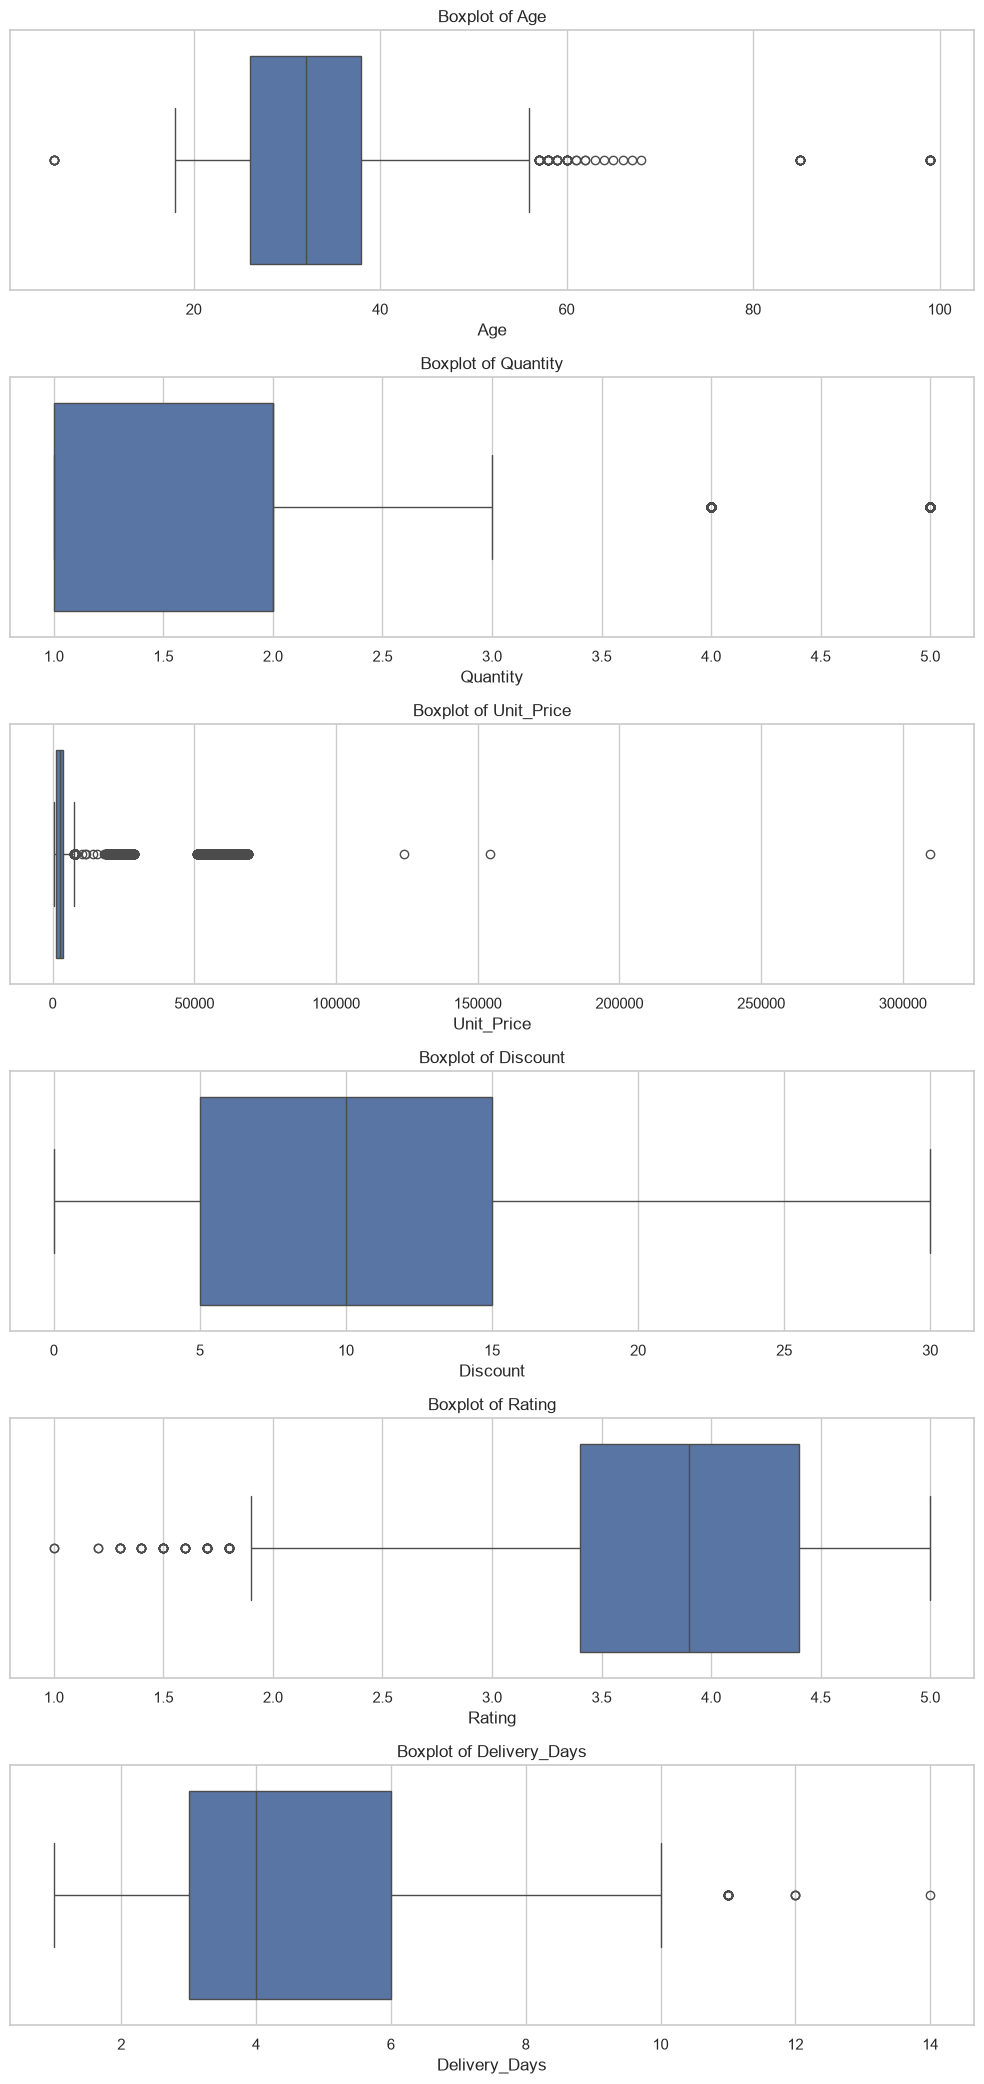

Potential outliers are flagged for review and are retained in the dataset.


In [5]:
outlier_summary = []
for column in numeric_columns:
    series = df[column].dropna()
    if series.empty:
        continue
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = int(((series < lower_bound) | (series > upper_bound)).sum())
    outlier_summary.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": count
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)

if numeric_columns:
    plot_columns = numeric_columns[: min(6, len(numeric_columns))]
    fig, axes = plt.subplots(len(plot_columns), 1, figsize=(10, 3.5 * len(plot_columns)))
    axes = np.atleast_1d(axes)
    for ax, column in zip(axes, plot_columns):
        sns.boxplot(x=df[column], ax=ax)
        ax.set_title(f"Boxplot of {column}")
    plt.tight_layout()
    plt.show()

print("Potential outliers are flagged for review and are retained in the dataset.")

## 6. Validate order amount against expected amount

In [6]:
def find_column(candidates):
    lookup = {str(column).strip().lower(): column for column in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

unit_price_col = find_column(["Unit_Price", "Unit Price", "Price"])
quantity_col = find_column(["Quantity", "Qty"])
discount_col = find_column(["Discount", "Discount_Rate", "Discount Rate"])
amount_col = find_column(["Total_Amount", "Total Amount", "Order_Amount", "Order Amount"])

required = [unit_price_col, quantity_col, amount_col]
if all(required):
    discount = pd.to_numeric(df[discount_col], errors="coerce").fillna(0) if discount_col else 0
    if isinstance(discount, pd.Series) and discount.max() > 1:
        discount = discount / 100
    expected = pd.to_numeric(df[unit_price_col], errors="coerce") * pd.to_numeric(df[quantity_col], errors="coerce") * (1 - discount)
    df["Expected_Amount"] = expected
    df["Amount_Difference"] = pd.to_numeric(df[amount_col], errors="coerce") - expected
    display(df[[unit_price_col, quantity_col] + ([discount_col] if discount_col else []) + [amount_col, "Expected_Amount", "Amount_Difference"]].head(10))
    print("Mean absolute difference:", df["Amount_Difference"].abs().mean())
else:
    print("Amount validation skipped. Required columns were not all found.")
    print("Detected columns:", {"Unit price": unit_price_col, "Quantity": quantity_col, "Discount": discount_col, "Total/order amount": amount_col})

,Unit_Price,Quantity,Discount,Total_Amount,Expected_Amount,Amount_Difference
0,2507.76,2,15.0,4263.19,4263.1920,-0.0020
1,1988.04,2,25.0,2982.06,2982.0600,0.0000
2,776.35,2,15.0,1319.80,1319.7950,0.0050
3,7739.89,1,10.0,6965.90,6965.9010,-0.0010
4,61138.76,1,5.0,58081.82,58081.8220,-0.0020
5,1890.11,1,10.0,1701.10,1701.0990,0.0010
6,5999.83,1,15.0,5099.86,5099.8555,0.0045
7,6760.65,1,20.0,5408.52,5408.5200,0.0000
8,2830.42,2,5.0,5377.80,5377.7980,0.0020
9,21716.46,2,10.0,39089.63,39089.6280,0.0020


Mean absolute difference: 7.786710233333405


## 7. Univariate analysis

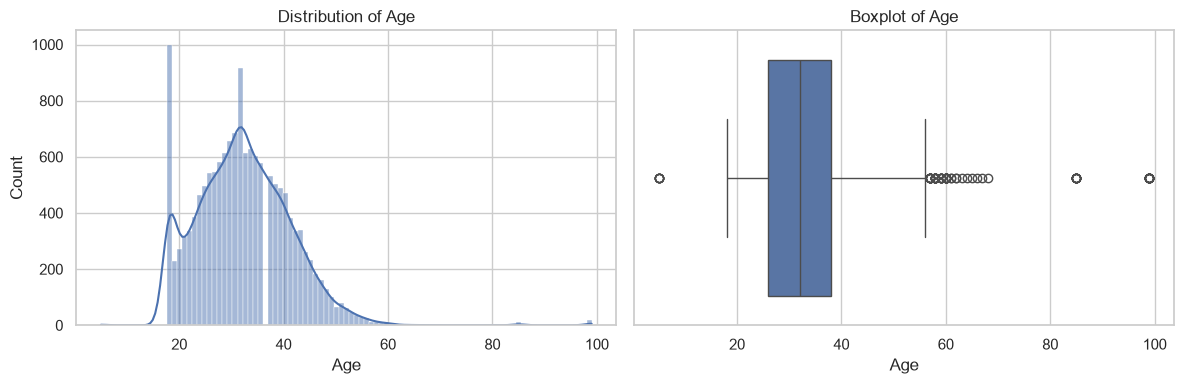

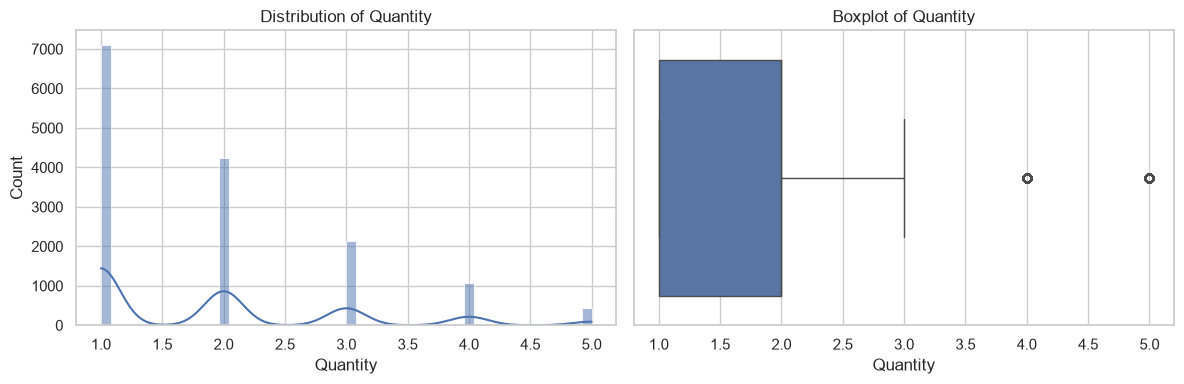

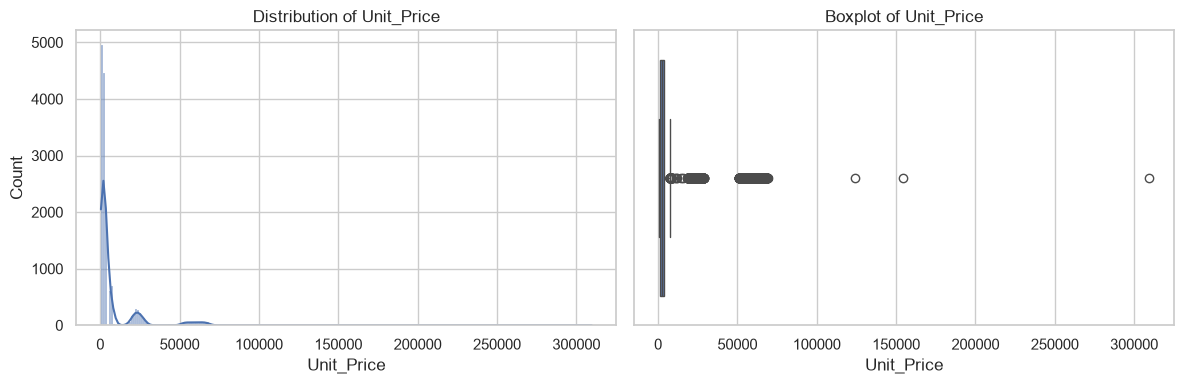

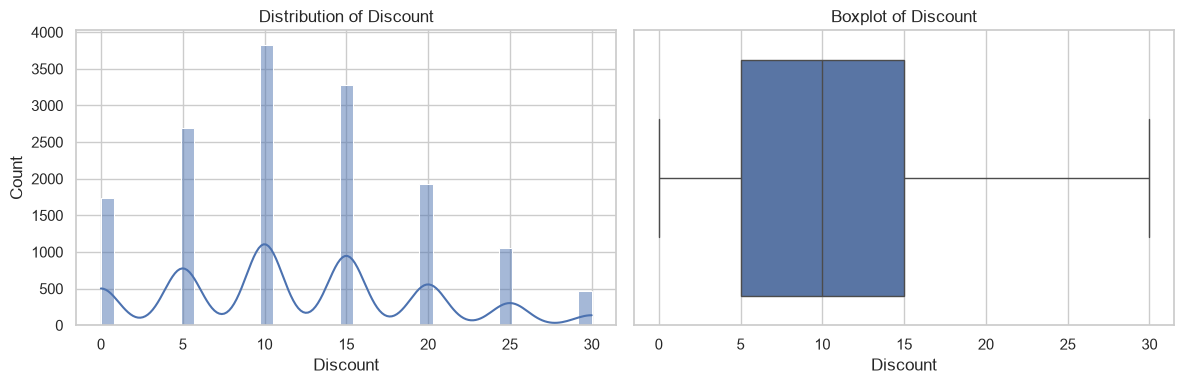

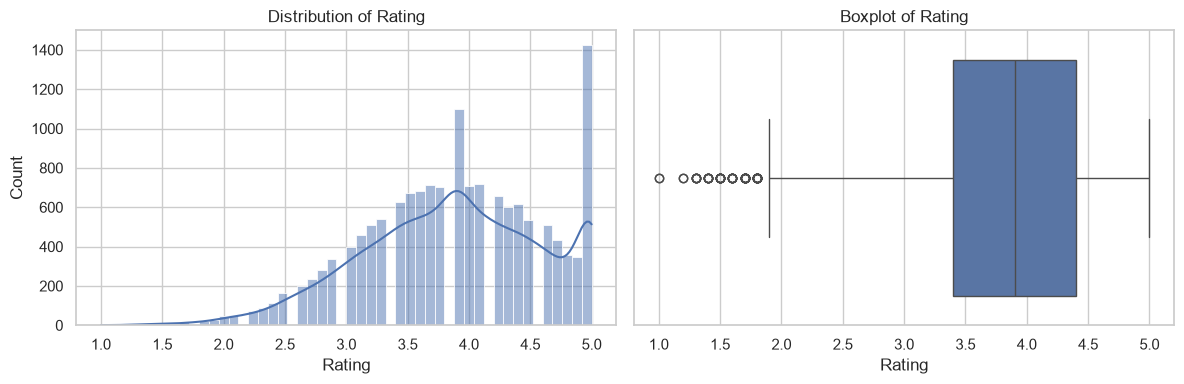

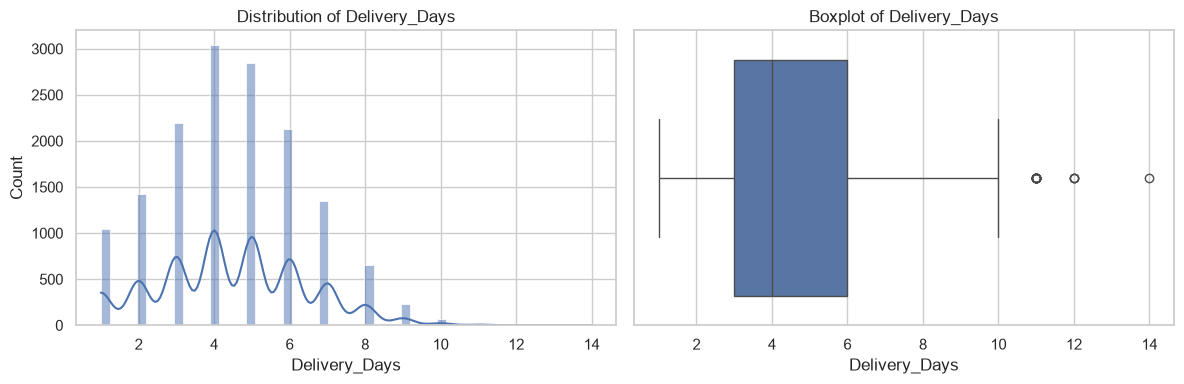

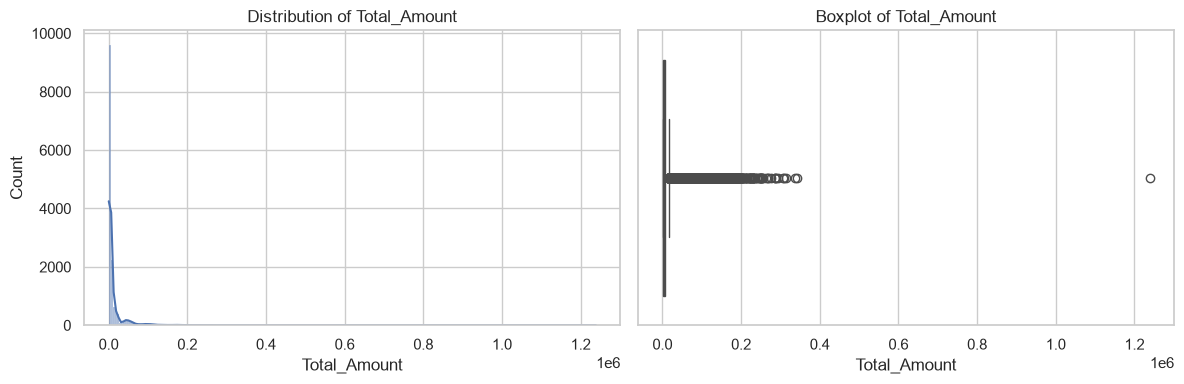

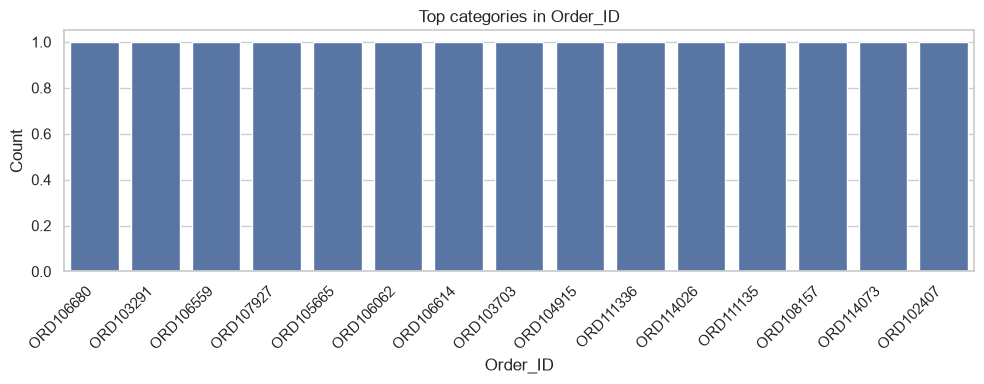

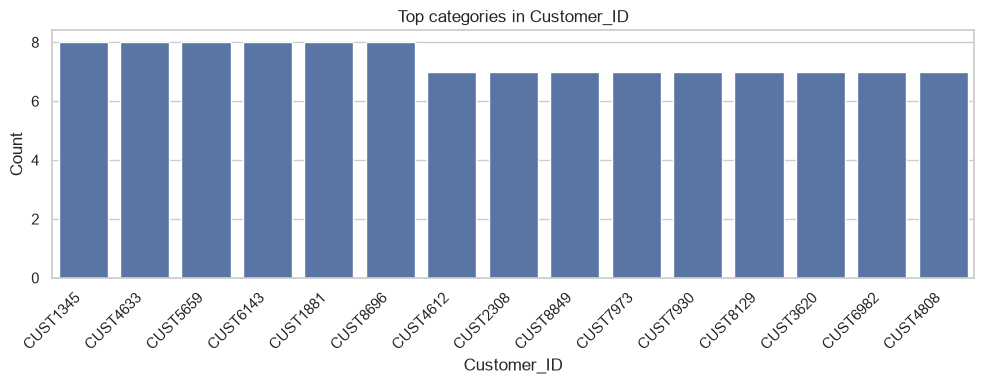

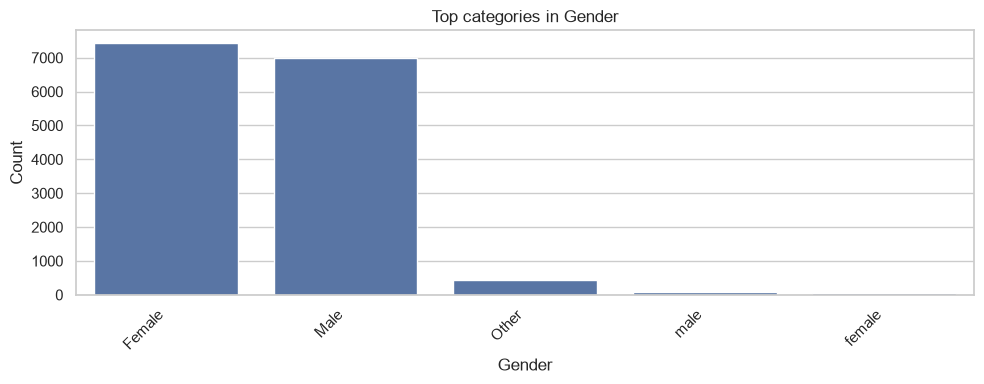

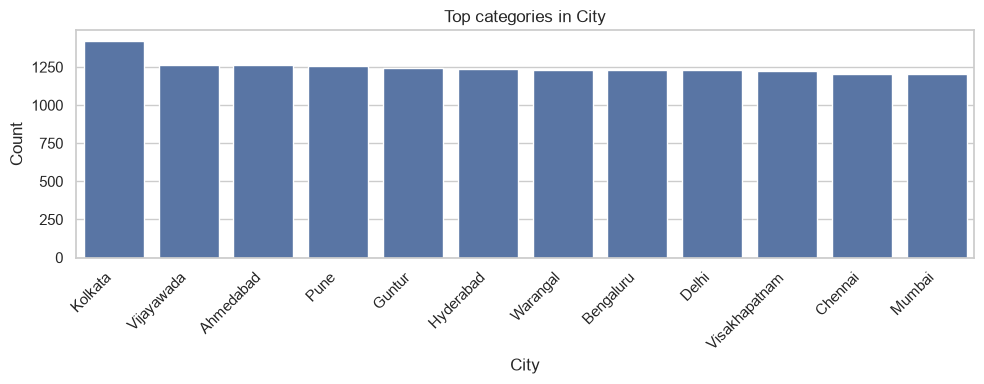

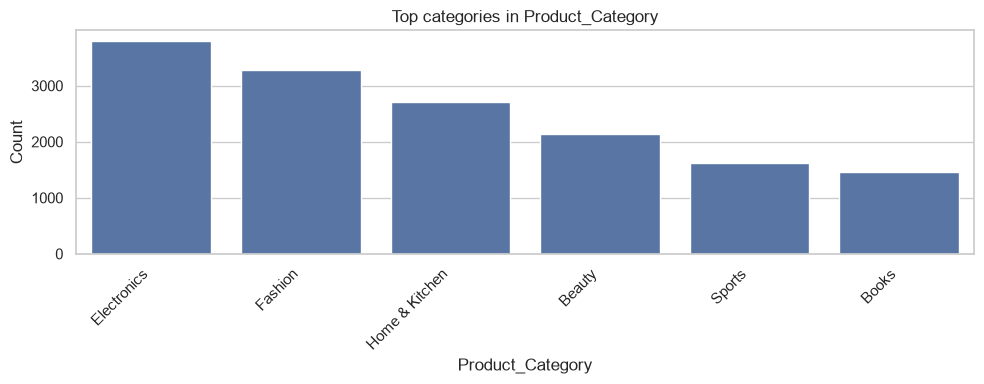

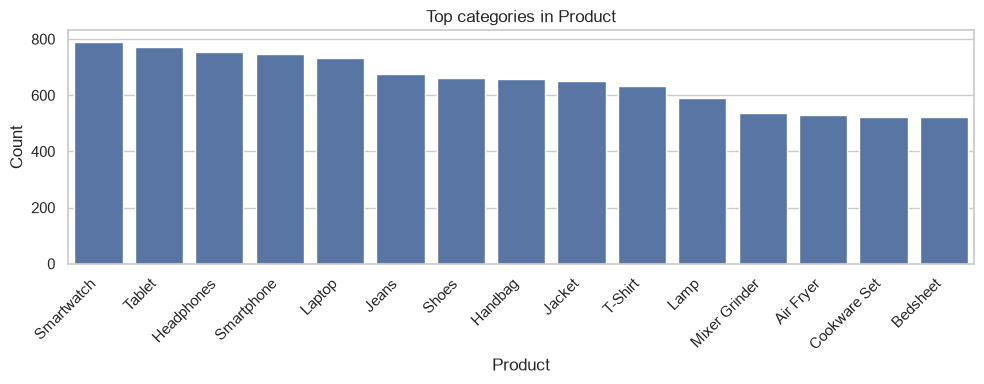

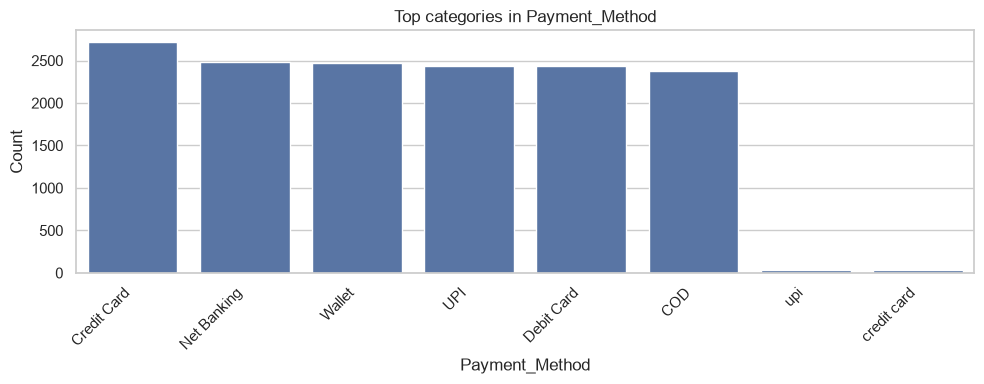

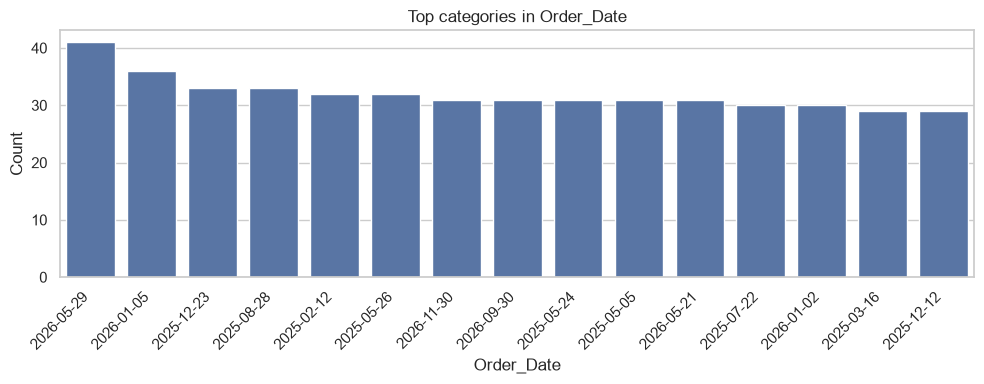

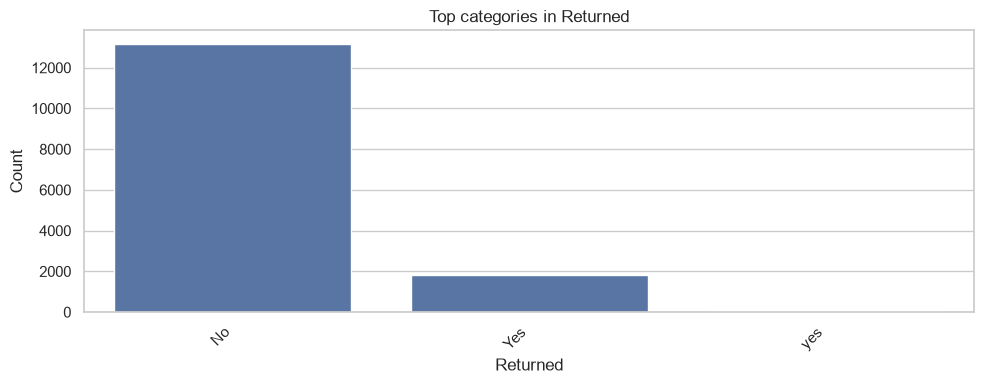

In [7]:
for column in numeric_columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df[column].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {column}")
    sns.boxplot(x=df[column], ax=axes[1])
    axes[1].set_title(f"Boxplot of {column}")
    plt.tight_layout()
    plt.show()

for column in categorical_columns:
    counts = df[column].value_counts().head(15)
    if not counts.empty:
        plt.figure(figsize=(10, 4))
        sns.barplot(x=counts.index.astype(str), y=counts.values)
        plt.title(f"Top categories in {column}")
        plt.xlabel(column)
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

## 8. Bivariate analysis

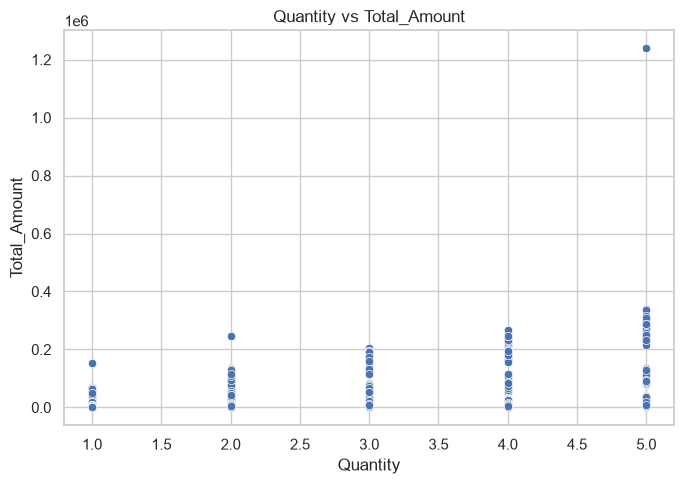

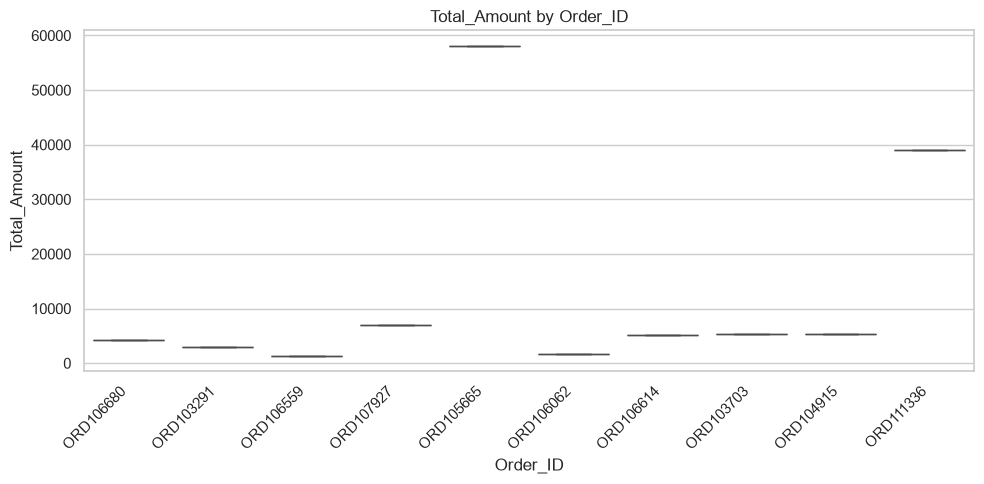

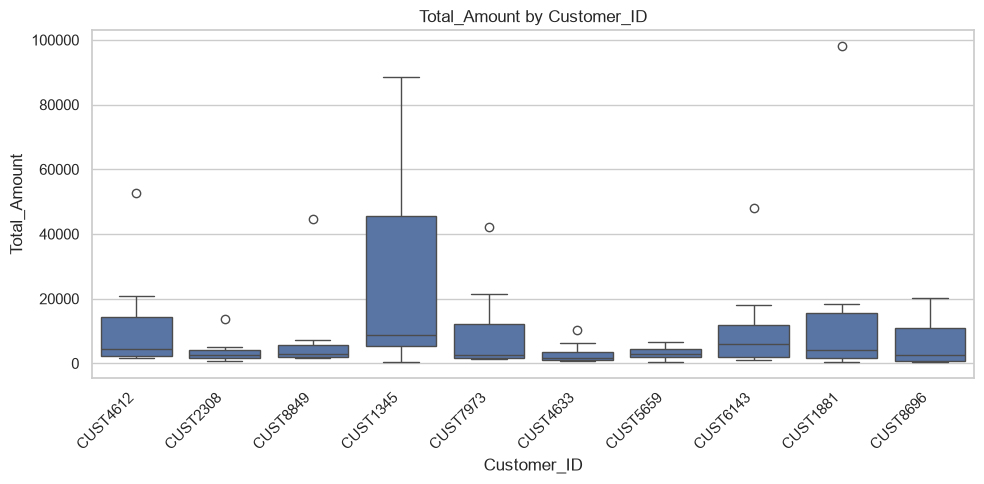

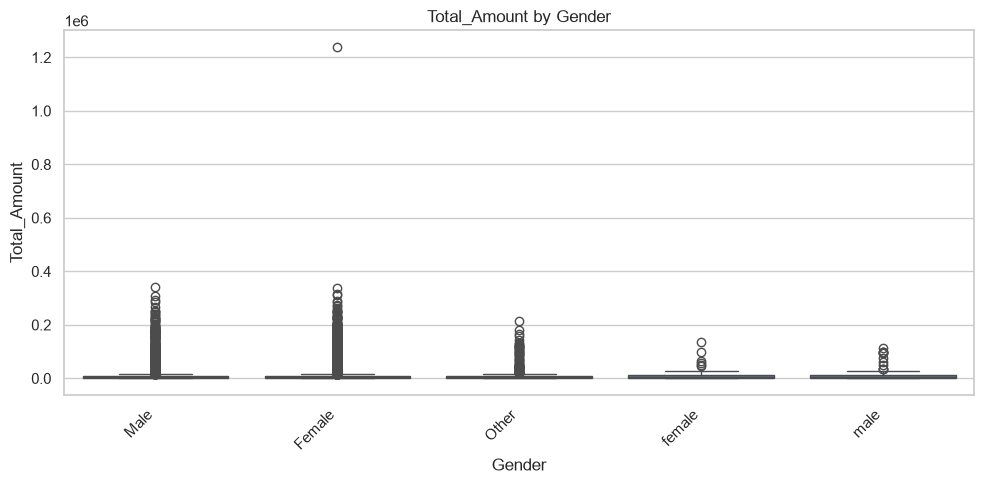

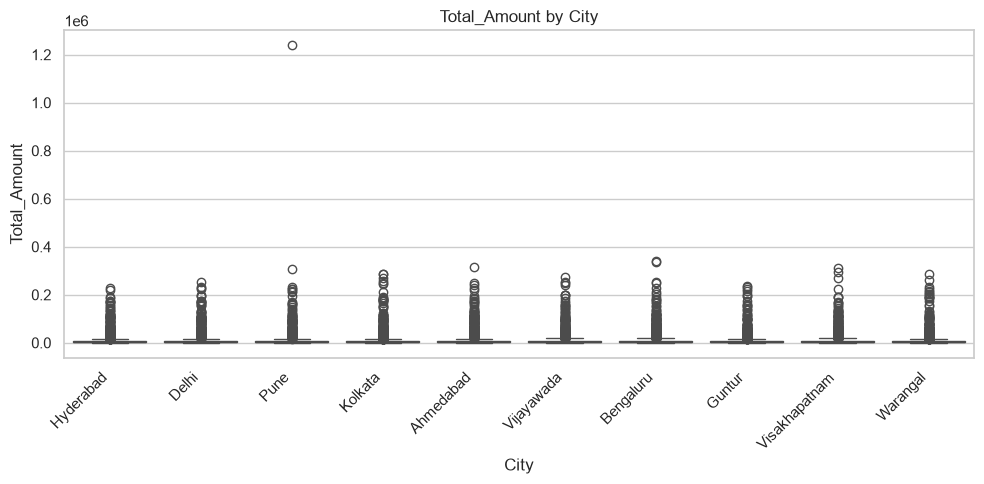

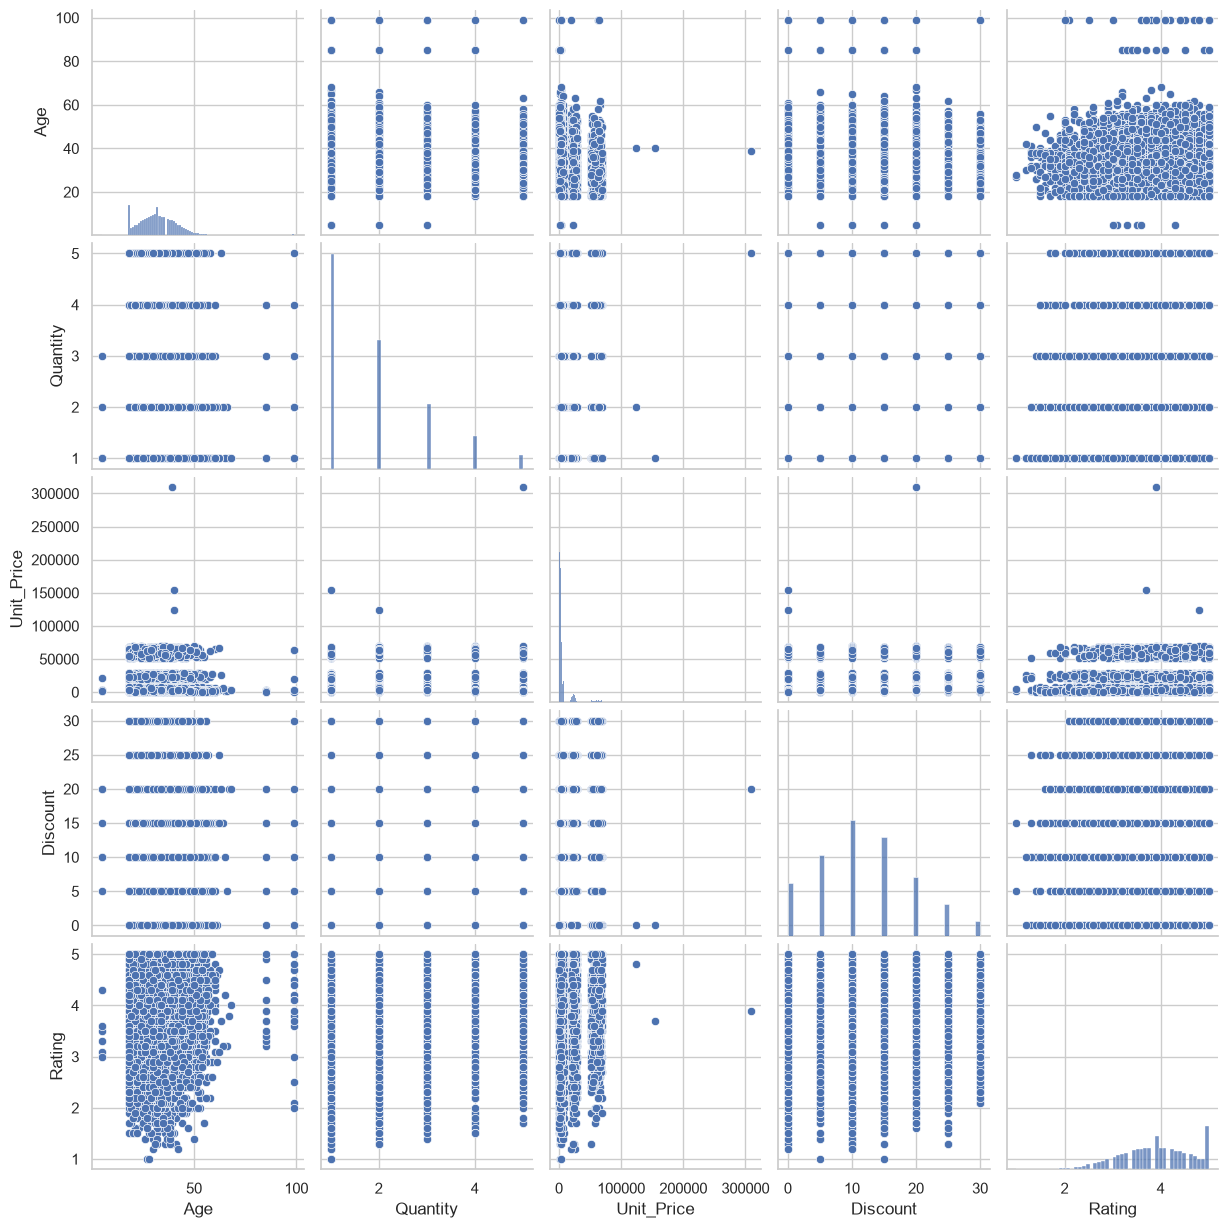

In [8]:
if amount_col and quantity_col:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x=quantity_col, y=amount_col)
    plt.title(f"{quantity_col} vs {amount_col}")
    plt.tight_layout()
    plt.show()

if amount_col:
    for column in categorical_columns[:4]:
        top_categories = df[column].value_counts().head(10).index
        subset = df[df[column].isin(top_categories)]
        if not subset.empty:
            plt.figure(figsize=(10, 5))
            sns.boxplot(data=subset, x=column, y=amount_col)
            plt.title(f"{amount_col} by {column}")
            plt.xticks(rotation=45, ha="right")
            plt.tight_layout()
            plt.show()

if len(numeric_columns) >= 2:
    sns.pairplot(df[numeric_columns[:5]].dropna())
    plt.show()

## 9. Multivariate analysis and correlation

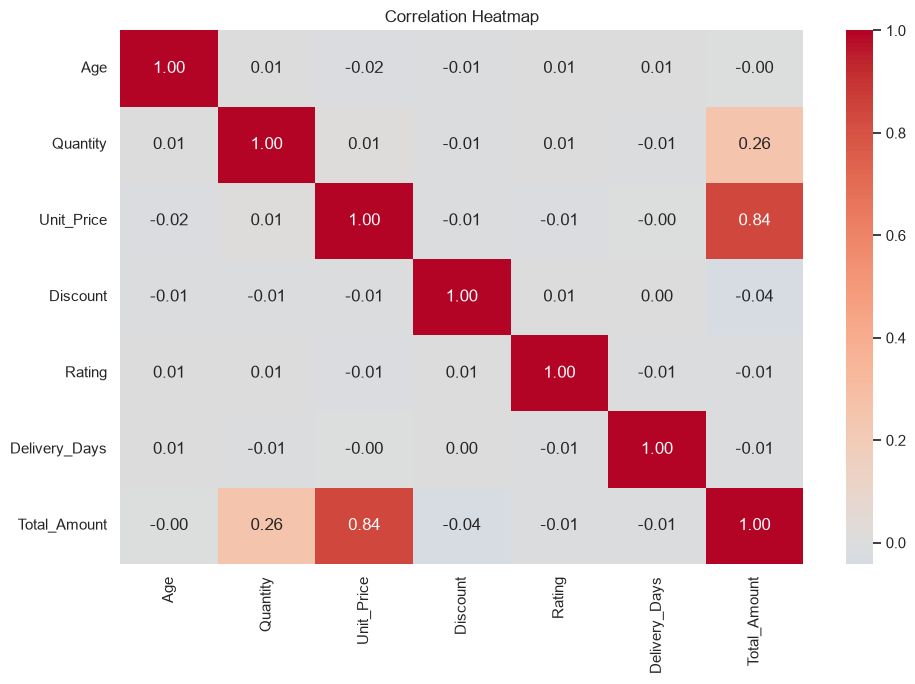

Correlation with Total_Amount:


,Pearson Correlation
Unit_Price,0.835066
Quantity,0.255942
Discount,-0.041234
Rating,-0.008006
Delivery_Days,-0.007124
Age,-0.004330


Strongest absolute linear association: Unit_Price = 0.835


In [9]:
if len(numeric_columns) >= 2:
    correlation = df[numeric_columns].corr(numeric_only=True)
    plt.figure(figsize=(10, 7))
    sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", center=0)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

if amount_col and amount_col in df.columns and pd.api.types.is_numeric_dtype(df[amount_col]):
    if len(numeric_columns) > 1:
        target_correlations = df[numeric_columns].corr(numeric_only=True)[amount_col].drop(amount_col)
        target_correlations = target_correlations.reindex(target_correlations.abs().sort_values(ascending=False).index)
        print(f"Correlation with {amount_col}:")
        display(target_correlations.to_frame("Pearson Correlation"))
        if not target_correlations.empty:
            print("Strongest absolute linear association:", target_correlations.index[0], "=", round(target_correlations.iloc[0], 3))
else:
    print("Correlation with total/order amount could not be calculated because a suitable numeric amount column was not found.")

## 10. Final cleaned data checks and export

In [10]:
print("Final dataset dimensions:", df.shape)
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Remaining duplicate rows:", int(df.duplicated().sum()))
if order_id_col:
    print("Remaining duplicate order IDs:", int(df.duplicated(subset=[order_id_col]).sum()))

output_file = "Pradeepthi_Cleaned_Ecommerce_Data.csv"
df.to_csv(output_file, index=False)
print(f"Cleaned dataset exported as: {output_file}")
display(df.head())

Final dataset dimensions: (15000, 18)
Remaining missing values: 0
Remaining duplicate rows: 0
Remaining duplicate order IDs: 0
Cleaned dataset exported as: Pradeepthi_Cleaned_Ecommerce_Data.csv


,Order_ID,Customer_ID,Age,Gender,City,Product_Category,Product,Quantity,Unit_Price,Discount,Payment_Method,Order_Date,Rating,Delivery_Days,Returned,Total_Amount,Expected_Amount,Amount_Difference
0,ORD106680,CUST7362,28.0,Male,Hyderabad,Fashion,Shoes,2,2507.76,15.0,Debit Card,2025-08-27,4.1,7.0,No,4263.19,4263.192,-0.002
1,ORD103291,CUST3155,30.0,Female,Delhi,Fashion,Jeans,2,1988.04,25.0,Debit Card,2025-06-18,4.2,4.0,No,2982.06,2982.060,0.000
2,ORD106559,CUST1349,32.0,Male,Pune,Sports,Yoga Mat,2,776.35,15.0,UPI,2025-01-13,3.6,2.0,No,1319.80,1319.795,0.005
3,ORD107927,CUST6779,39.0,Female,Chennai,Electronics,Smartwatch,1,7739.89,10.0,UPI,2026-06-01,3.2,6.0,Yes,6965.90,6965.901,-0.001
4,ORD105665,CUST1389,27.0,Male,Chennai,Electronics,Laptop,1,61138.76,5.0,Debit Card,2026-06-17,3.1,5.0,No,58081.82,58081.822,-0.002


## 11. Conclusion

The e-commerce dataset was examined using Pandas, NumPy, Matplotlib and Seaborn. The analysis included an initial inspection of the raw data, numerical and categorical summaries, missing-value handling, category standardization and removal of repeated order IDs.

Potential outliers were identified using boxplots and the IQR method. They were retained because unusual values are not necessarily errors and should be reviewed with business context. The order amount was also compared with an expected amount calculated from unit price, quantity and discount, where the required columns were available.

Univariate, bivariate and multivariate visualizations were used to explore customer and order patterns. The correlation analysis identifies which numerical variables have the strongest linear association with the total/order amount; the exact values and most frequent categories are displayed by the notebook when it is run.

The final cleaned dataset is exported as `Pradeepthi_Cleaned_Ecommerce_Data.csv` and can be used for further exploratory analysis. All relationships discussed are observational and should not be interpreted as causal.